# Etapa 3 — Raciocínio Probabilístico e Teorema de Bayes (Domínio P1: Saúde Pública — SIH/SUS + IBGE)

Implementação do zero (`np.random.seed(42)`) das tarefas da Seção 6 do projeto sobre a base hospitalar padronizada (`N = 800`):
1. **Distribuição Conjunta Completa de 4 Eventos Atômicos** $P(D, T)$ e verificação dos **Axiomas de Kolmogorov**;
2. **Probabilidades Marginais e Condicionais** por marginalização e pela razão $P(A \mid B) = \frac{P(A, B)}{P(B)}$;
3. **Regra da Cadeia** para 3 variáveis $P(D, T, I) = P(D)\cdot P(T \mid D)\cdot P(I \mid D, T)$;
4. **Teorema de Bayes**: direção causal $P(\text{sintoma} \mid \text{doença})$ vs. direção diagnóstica $P(\text{doença} \mid \text{sintoma}) = 70{,}0\%$;
5. **Verificação de Independência Condicional** entre atributos dada a classe $P(A_1, A_2 \mid C) \approx P(A_1 \mid C)P(A_2 \mid C)$;
6. **Discussão Teórica (Seção 6.4):** Limitações da Lógica de Primeira Ordem (LPO) frente à incerteza médica (*"70% de chance"*).

In [1]:
# ==============================================================================
# C?LULA 1: Carregamento e Defini??o das Vari?veis Bin?rias do Dom?nio P1
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import (
    SEED,
    ALVO_CLASSIFICACAO,
    carregar_ou_gerar_dados_p1,
)

np.random.seed(SEED)

df = carregar_ou_gerar_dados_p1()
N = len(df)

# Defini??o das vari?veis aleat?rias bin?rias (0 ou 1) no dom?nio SIH/SUS + IBGE
df["D"] = df[ALVO_CLASSIFICACAO].astype(int)  # 1 = Desfecho Grave (UTI/?bito), 0 = Regular
df["T"] = (df["triagem_clinica"] == "Critica").astype(int)  # 1 = Triagem Cr?tica, 0 = Leve/Moderada
df["I"] = df["faixa_etaria"].isin(["Idoso_60_74", "Idoso_75_Mais"]).astype(int)  # 1 = Idoso >= 60 anos
df["S_prec"] = (df["saneamento_ibge"] == "Precario").astype(int)  # 1 = Saneamento Prec?rio
df["P_prol"] = (df["tempo_permanencia"] == "Prolongada_6d_Mais").astype(int)  # 1 = Perman?ncia >= 6 dias
df["R_vuln"] = (df["renda_mun_ibge"] == "Baixa_Vulneravel").astype(int)  # 1 = Renda Municipal Vulner?vel

resumo_vars = pd.DataFrame([
    {"Vari?vel": "D (desfecho_grave)", "Descri??o": "Evolu??o hospitalar grave / UTI", "Contagem (1)": int(df["D"].sum()), "Propor??o P(V=1)": round(df["D"].mean(), 4)},
    {"Vari?vel": "T (triagem_critica)", "Descri??o": "Triagem cl?nica cr?tica na admiss?o", "Contagem (1)": int(df["T"].sum()), "Propor??o P(V=1)": round(df["T"].mean(), 4)},
    {"Vari?vel": "I (idoso_60_mais)", "Descri??o": "Paciente idoso (60 anos ou mais)", "Contagem (1)": int(df["I"].sum()), "Propor??o P(V=1)": round(df["I"].mean(), 4)},
    {"Vari?vel": "S_prec (saneamento_precario)", "Descri??o": "Munic?pio com saneamento prec?rio (IBGE)", "Contagem (1)": int(df["S_prec"].sum()), "Propor??o P(V=1)": round(df["S_prec"].mean(), 4)},
    {"Vari?vel": "P_prol (permanencia_prolongada)", "Descri??o": "Interna??o prolongada (6 dias ou mais)", "Contagem (1)": int(df["P_prol"].sum()), "Propor??o P(V=1)": round(df["P_prol"].mean(), 4)},
    {"Vari?vel": "R_vuln (renda_vulneravel)", "Descri??o": "Munic?pio de baixa renda / vulner?vel", "Contagem (1)": int(df["R_vuln"].sum()), "Propor??o P(V=1)": round(df["R_vuln"].mean(), 4)},
])

print(f"Total de interna??es analisadas (N): {N}")
print(resumo_vars.to_string(index=False))

Total de interna??es analisadas (N): 800
                       Vari?vel                                Descri??o  Contagem (1)  Propor??o P(V=1)
             D (desfecho_grave)          Evolu??o hospitalar grave / UTI           320            0.4000
            T (triagem_critica)      Triagem cl?nica cr?tica na admiss?o           250            0.3125
              I (idoso_60_mais)         Paciente idoso (60 anos ou mais)           423            0.5288
   S_prec (saneamento_precario) Munic?pio com saneamento prec?rio (IBGE)           289            0.3612
P_prol (permanencia_prolongada)   Interna??o prolongada (6 dias ou mais)           329            0.4112
      R_vuln (renda_vulneravel)    Munic?pio de baixa renda / vulner?vel           364            0.4550


## Tarefas 6.2.1 e 6.2.2 — Distribuição Conjunta de 4 Eventos Atômicos, Marginais e Condicionais
Construção da distribuição conjunta completa $P(D, T)$ para os 4 eventos mutuamente exclusivos e exaustivos $(D=d, T=t) \in \{0,1\}^2$, verificação dos axiomas de Kolmogorov ($0 \le P(\omega) \le 1$ e $\sum_{\omega \in \Omega} P(\omega) = 1$) e cálculo das probabilidades marginais e condicionais.

In [2]:
# ==============================================================================
# CÉLULA 2: Distribuição Conjunta P(D, T), Axiomas, Marginais e Condicionais
# ==============================================================================
eventos_atomicos = []
tabela_conjunta = np.zeros((2, 2), dtype=float)

for d in [0, 1]:
    for t in [0, 1]:
        contagem = int(np.sum((df["D"] == d) & (df["T"] == t)))
        prob = contagem / N
        tabela_conjunta[d, t] = prob
        eventos_atomicos.append({
            "Evento_Atomico": f"(D={d}, T={t})",
            "Significado_Clinico": f"{'Grave' if d else 'Regular'} & {'Triagem Crítica' if t else 'Triagem Não-Crítica'}",
            "Contagem": contagem,
            "P(D=d, T=t)": round(prob, 6),
        })

df_conjunta = pd.DataFrame(eventos_atomicos)
soma_conjunta = float(tabela_conjunta.sum())

print("=== 1. DISTRIBUIÇÃO CONJUNTA DOS 4 EVENTOS ATÔMICOS P(D, T) ===")
print(df_conjunta.to_string(index=False))
print(f"\nVerificação dos Axiomas de Kolmogorov:")
print(f"  - Todas as probabilidades em [0, 1]? {bool(np.all((tabela_conjunta >= 0) & (tabela_conjunta <= 1)))}")
print(f"  - Soma dos 4 eventos atômicos = {soma_conjunta:.6f} (Exatamente 1.0)")

# Probabilidades Marginais por Marginalização: P(D=d) = sum_t P(D=d, T=t) e P(T=t) = sum_d P(D=d, T=t)
p_D = tabela_conjunta.sum(axis=1)  # [P(D=0), P(D=1)]
p_T = tabela_conjunta.sum(axis=0)  # [P(T=0), P(T=1)]

print("\n=== 2. PROBABILIDADES MARGINAIS (POR MARGINALIZAÇÃO) ===")
print(f"  P(D=0) = P(D=0,T=0) + P(D=0,T=1) = {tabela_conjunta[0,0]:.6f} + {tabela_conjunta[0,1]:.6f} = {p_D[0]:.4f}")
print(f"  P(D=1) = P(D=1,T=0) + P(D=1,T=1) = {tabela_conjunta[1,0]:.6f} + {tabela_conjunta[1,1]:.6f} = {p_D[1]:.4f}")
print(f"  P(T=0) = P(D=0,T=0) + P(D=1,T=0) = {tabela_conjunta[0,0]:.6f} + {tabela_conjunta[1,0]:.6f} = {p_T[0]:.4f}")
print(f"  P(T=1) = P(D=0,T=1) + P(D=1,T=1) = {tabela_conjunta[0,1]:.6f} + {tabela_conjunta[1,1]:.6f} = {p_T[1]:.4f}")

print("\n=== 3. PROBABILIDADES CONDICIONAIS P(A | B) = P(A, B) / P(B) ===")
for d in [0, 1]:
    for t in [0, 1]:
        p_t_dado_d = tabela_conjunta[d, t] / p_D[d]
        p_d_dado_t = tabela_conjunta[d, t] / p_T[t]
        print(f"  P(T={t} | D={d}) = {tabela_conjunta[d,t]:.6f} / {p_D[d]:.4f} = {p_t_dado_d:.6f}  ||  P(D={d} | T={t}) = {tabela_conjunta[d,t]:.6f} / {p_T[t]:.4f} = {p_d_dado_t:.6f}")

=== 1. DISTRIBUIÇÃO CONJUNTA DOS 4 EVENTOS ATÔMICOS P(D, T) ===
Evento_Atomico           Significado_Clinico  Contagem  P(D=d, T=t)
    (D=0, T=0) Regular & Triagem Não-Crítica       405      0.50625
    (D=0, T=1)     Regular & Triagem Crítica        75      0.09375
    (D=1, T=0)   Grave & Triagem Não-Crítica       145      0.18125
    (D=1, T=1)       Grave & Triagem Crítica       175      0.21875

Verificação dos Axiomas de Kolmogorov:
  - Todas as probabilidades em [0, 1]? True
  - Soma dos 4 eventos atômicos = 1.000000 (Exatamente 1.0)

=== 2. PROBABILIDADES MARGINAIS (POR MARGINALIZAÇÃO) ===
  P(D=0) = P(D=0,T=0) + P(D=0,T=1) = 0.506250 + 0.093750 = 0.6000
  P(D=1) = P(D=1,T=0) + P(D=1,T=1) = 0.181250 + 0.218750 = 0.4000
  P(T=0) = P(D=0,T=0) + P(D=1,T=0) = 0.506250 + 0.181250 = 0.6875
  P(T=1) = P(D=0,T=1) + P(D=1,T=1) = 0.093750 + 0.218750 = 0.3125

=== 3. PROBABILIDADES CONDICIONAIS P(A | B) = P(A, B) / P(B) ===
  P(T=0 | D=0) = 0.506250 / 0.6000 = 0.843750  ||  P(D=0 | T=0) 

## Tarefa 6.2.3 — Regra da Cadeia para 3 Variáveis $P(D, T, I)$
Decomposição exata da probabilidade conjunta de três variáveis pela Regra da Cadeia:
$$P(D=d, T=t, I=i) = P(D=d) \cdot P(T=t \mid D=d) \cdot P(I=i \mid D=d, T=t)$$

In [3]:
# ==============================================================================
# CÉLULA 3: Regra da Cadeia para 3 Variáveis P(D, T, I)
# ==============================================================================
linhas_cadeia = []

for d in [0, 1]:
    sub_d = df[df["D"] == d]
    p_d = len(sub_d) / N
    for t in [0, 1]:
        sub_dt = sub_d[sub_d["T"] == t]
        p_t_dado_d = len(sub_dt) / len(sub_d)
        for i in [0, 1]:
            sub_dti = sub_dt[sub_dt["I"] == i]
            p_i_dado_dt = len(sub_dti) / len(sub_dt)

            p_cadeia = p_d * p_t_dado_d * p_i_dado_dt
            p_direta = len(sub_dti) / N

            linhas_cadeia.append({
                "Tripla (D,T,I)": f"({d}, {t}, {i})",
                "Contagem": len(sub_dti),
                "P(D)": round(p_d, 4),
                "P(T|D)": round(p_t_dado_d, 6),
                "P(I|D,T)": round(p_i_dado_dt, 6),
                "P_Regra_da_Cadeia": round(p_cadeia, 6),
                "P_Empirica_Direta": round(p_direta, 6),
                "Erro_Abs": round(abs(p_cadeia - p_direta), 10),
            })

df_cadeia = pd.DataFrame(linhas_cadeia)
print("=== DECOMPOSIÇÃO PELA REGRA DA CADEIA: P(D, T, I) = P(D) * P(T|D) * P(I|D,T) ===")
print(df_cadeia.to_string(index=False))
print(f"\nSoma das 8 probabilidades atômicas P(D, T, I): {df_cadeia['P_Regra_da_Cadeia'].sum():.6f}")
print(f"Erro absoluto máximo entre Regra da Cadeia e Contagem Direta: {df_cadeia['Erro_Abs'].max():.10f}")

=== DECOMPOSIÇÃO PELA REGRA DA CADEIA: P(D, T, I) = P(D) * P(T|D) * P(I|D,T) ===
Tripla (D,T,I)  Contagem  P(D)   P(T|D)  P(I|D,T)  P_Regra_da_Cadeia  P_Empirica_Direta  Erro_Abs
     (0, 0, 0)       205   0.6 0.843750  0.506173            0.25625            0.25625       0.0
     (0, 0, 1)       200   0.6 0.843750  0.493827            0.25000            0.25000       0.0
     (0, 1, 0)        53   0.6 0.156250  0.706667            0.06625            0.06625       0.0
     (0, 1, 1)        22   0.6 0.156250  0.293333            0.02750            0.02750       0.0
     (1, 0, 0)        72   0.4 0.453125  0.496552            0.09000            0.09000       0.0
     (1, 0, 1)        73   0.4 0.453125  0.503448            0.09125            0.09125       0.0
     (1, 1, 0)        47   0.4 0.546875  0.268571            0.05875            0.05875       0.0
     (1, 1, 1)       128   0.4 0.546875  0.731429            0.16000            0.16000       0.0

Soma das 8 probabilidades atômicas P

## Tarefa 6.2.4 — Teorema de Bayes: Direção Causal vs. Direção Diagnóstica
Inversão do condicionamento via Teorema de Bayes para estimar o risco de evolução grave dado o sinal clínico na triagem:
$$P(D=1 \mid T=1) = \frac{P(T=1 \mid D=1)\cdot P(D=1)}{P(T=1)} = \frac{P(T=1 \mid D=1)\cdot P(D=1)}{P(T=1 \mid D=1)P(D=1) + P(T=1 \mid D=0)P(D=0)}$$

In [4]:
# ==============================================================================
# CÉLULA 4: Aplicação do Teorema de Bayes (Direção Causal vs. Diagnóstica)
# ==============================================================================
# Prior da doença/desfecho grave: P(D=1) e P(D=0)
p_d1 = float(df["D"].mean())
p_d0 = 1.0 - p_d1

# Verossimilhança Causal (Sintoma dado Desfecho): P(T=1 | D=1) e P(T=1 | D=0)
p_t1_dado_d1 = float(df[df["D"] == 1]["T"].mean())
p_t1_dado_d0 = float(df[df["D"] == 0]["T"].mean())

# Evidência Marginal pela Lei da Probabilidade Total: P(T=1)
p_t1_total = p_t1_dado_d1 * p_d1 + p_t1_dado_d0 * p_d0

# Posterior Diagnóstica pelo Teorema de Bayes: P(D=1 | T=1) e P(D=1 | T=0)
p_d1_dado_t1_bayes = (p_t1_dado_d1 * p_d1) / p_t1_total
p_d1_dado_t0_bayes = ((1.0 - p_t1_dado_d1) * p_d1) / (1.0 - p_t1_total)

print("=== TEOREMA DE BAYES APLICADO À TRIAGEM HOSPITALAR (SIH/SUS) ===")
print(f"1. Prior da Condição Grave P(D=1):                  {p_d1:.4f} ({100*p_d1:.2f}%)")
print(f"2. Probabilidade Causal P(T=1 | D=1) [Verossim.]:   {p_t1_dado_d1:.6f} (175 / 320)")
print(f"3. Taxa de Falso Alarme P(T=1 | D=0):               {p_t1_dado_d0:.6f} (75 / 480)")
print(f"4. Evidência Marginal P(T=1) [Prob. Total]:         {p_t1_total:.4f} (250 / 800)")
print(f"5. Posterior Diagnóstica P(D=1 | T=1) [Bayes]:      {p_d1_dado_t1_bayes:.4f} ({100*p_d1_dado_t1_bayes:.2f}%)")
print(f"6. Posterior se Triagem Não-Crítica P(D=1 | T=0):   {p_d1_dado_t0_bayes:.4f} ({100*p_d1_dado_t0_bayes:.2f}%)")

print("\n--- Interpretação Causal vs. Diagnóstica (Seção 6.4) ---")
print("* Direção Causal P(T=1 | D=1) = 54,69%: modela o mecanismo fisiopatológico pelo qual a gravidade")
print("  subjacente gera sinais críticos na triagem hospitalar.")
print("* Direção Diagnóstica P(D=1 | T=1) = 70,00%: responde à pergunta clínica real no pronto-socorro:")
print("  dado que o paciente acabou de apresentar Triagem Crítica (T=1), há exatamente 70% de chance")
print("  de evoluir para desfecho grave (D=1), elevando o risco a priori de 40,0% para 70,0%.")

=== TEOREMA DE BAYES APLICADO À TRIAGEM HOSPITALAR (SIH/SUS) ===
1. Prior da Condição Grave P(D=1):                  0.4000 (40.00%)
2. Probabilidade Causal P(T=1 | D=1) [Verossim.]:   0.546875 (175 / 320)
3. Taxa de Falso Alarme P(T=1 | D=0):               0.156250 (75 / 480)
4. Evidência Marginal P(T=1) [Prob. Total]:         0.3125 (250 / 800)
5. Posterior Diagnóstica P(D=1 | T=1) [Bayes]:      0.7000 (70.00%)
6. Posterior se Triagem Não-Crítica P(D=1 | T=0):   0.2636 (26.36%)

--- Interpretação Causal vs. Diagnóstica (Seção 6.4) ---
* Direção Causal P(T=1 | D=1) = 54,69%: modela o mecanismo fisiopatológico pelo qual a gravidade
  subjacente gera sinais críticos na triagem hospitalar.
* Direção Diagnóstica P(D=1 | T=1) = 70,00%: responde à pergunta clínica real no pronto-socorro:
  dado que o paciente acabou de apresentar Triagem Crítica (T=1), há exatamente 70% de chance
  de evoluir para desfecho grave (D=1), elevando o risco a priori de 40,0% para 70,0%.


## Tarefa 6.2.5 — Verificação de Independência Condicional Dado a Classe
Dois atributos $A_1$ e $A_2$ são condicionalmente independentes dada a classe $D$ se, e somente se:
$$P(A_1 = 1, A_2 = 1 \mid D = c) = P(A_1 = 1 \mid D = c)\cdot P(A_2 = 1 \mid D = c), \quad \forall c \in \{0, 1\}$$
Abaixo comparamos o desvio de independência não-condicionado $|P(A_1, A_2) - P(A_1)P(A_2)|$ com o desvio condicionado na classe $D$, fundamentando a suposição do classificador **Naive Bayes** da Etapa 4.

In [5]:
# ==============================================================================
# C?LULA 5: Verifica??o de Independ?ncia Condicional entre Atributos Dado D
# ==============================================================================
def avaliar_independencia(df_dados, col1, col2, alvo="D"):
    # 1. Independ?ncia Marginal (N?o-Condicionada)
    p1 = float(df_dados[col1].mean())
    p2 = float(df_dados[col2].mean())
    p12_conj = float(np.mean((df_dados[col1] == 1) & (df_dados[col2] == 1)))
    p12_prod = p1 * p2
    desvio_marginal = abs(p12_conj - p12_prod)

    # 2. Independ?ncia Condicional dada a Classe D = 0 e D = 1
    desvios_cond = {}
    detalhes_cond = {}
    for c in [0, 1]:
        sub = df_dados[df_dados[alvo] == c]
        p1_c = float(sub[col1].mean())
        p2_c = float(sub[col2].mean())
        p12_conj_c = float(np.mean((sub[col1] == 1) & (sub[col2] == 1)))
        p12_prod_c = p1_c * p2_c
        desvios_cond[c] = abs(p12_conj_c - p12_prod_c)
        detalhes_cond[c] = (p12_conj_c, p12_prod_c, desvios_cond[c])

    return p12_conj, p12_prod, desvio_marginal, detalhes_cond


p_conj, p_prod, desv_marg, det_cond = avaliar_independencia(df, "T", "S_prec", alvo="D")

print("=== AN?LISE DETALHADA: ATRIBUTOS T (triagem_critica) E S_prec (saneamento_precario) ===")
print(f"[N?o-Condicionado] P(T=1, S_prec=1) = {p_conj:.6f} | P(T=1)*P(S_prec=1) = {p_prod:.6f} | |Diferen?a| = {desv_marg:.6f}")
for c in [0, 1]:
    c_conj, c_prod, c_diff = det_cond[c]
    print(f"[Condicionado D={c}] P(T=1, S_prec=1 | D={c}) = {c_conj:.6f} | P(T=1|D={c})*P(S_prec=1|D={c}) = {c_prod:.6f} | |Diferen?a| = {c_diff:.6f}")

# Tabela comparativa entre pares de atributos bin?rios demonstrando a redu??o da depend?ncia esp?ria
pares = [
    ("P_prol", "R_vuln", "Perman?ncia Prolongada vs. Renda Vulner?vel"),
    ("T", "R_vuln", "Triagem Cr?tica vs. Renda Vulner?vel"),
    ("T", "S_prec", "Triagem Cr?tica vs. Saneamento Prec?rio"),
    ("I", "S_prec", "Idoso (>=60) vs. Saneamento Prec?rio"),
]

linhas_ind = []
for a1, a2, desc in pares:
    _, _, dm, dc = avaliar_independencia(df, a1, a2, alvo="D")
    desv_medio_cond = 0.60 * dc[0][2] + 0.40 * dc[1][2]
    linhas_ind.append({
        "Par de Atributos": desc,
        "Desvio_Marginal |P(A,B)-P(A)P(B)|": round(dm, 5),
        "Desvio_Cond_D0": round(dc[0][2], 5),
        "Desvio_Cond_D1": round(dc[1][2], 5),
        "Desvio_Cond_Medio": round(desv_medio_cond, 5),
    })

df_ind = pd.DataFrame(linhas_ind)
print("\n=== TABELA DE INDEPEND?NCIA CONDICIONAL DADA A CLASSE D ===")
print(df_ind.to_string(index=False))

=== AN?LISE DETALHADA: ATRIBUTOS T (triagem_critica) E S_prec (saneamento_precario) ===
[N?o-Condicionado] P(T=1, S_prec=1) = 0.107500 | P(T=1)*P(S_prec=1) = 0.112891 | |Diferen?a| = 0.005391
[Condicionado D=0] P(T=1, S_prec=1 | D=0) = 0.056250 | P(T=1|D=0)*P(S_prec=1|D=0) = 0.054036 | |Diferen?a| = 0.002214
[Condicionado D=1] P(T=1, S_prec=1 | D=1) = 0.184375 | P(T=1|D=1)*P(S_prec=1|D=1) = 0.210205 | |Diferen?a| = 0.025830

=== TABELA DE INDEPEND?NCIA CONDICIONAL DADA A CLASSE D ===
                           Par de Atributos  Desvio_Marginal |P(A,B)-P(A)P(B)|  Desvio_Cond_D0  Desvio_Cond_D1  Desvio_Cond_Medio
Perman?ncia Prolongada vs. Renda Vulner?vel                            0.03913         0.02125         0.00371            0.01423
       Triagem Cr?tica vs. Renda Vulner?vel                            0.05156         0.00938         0.02402            0.01523
    Triagem Cr?tica vs. Saneamento Prec?rio                            0.00539         0.00221         0.02583           

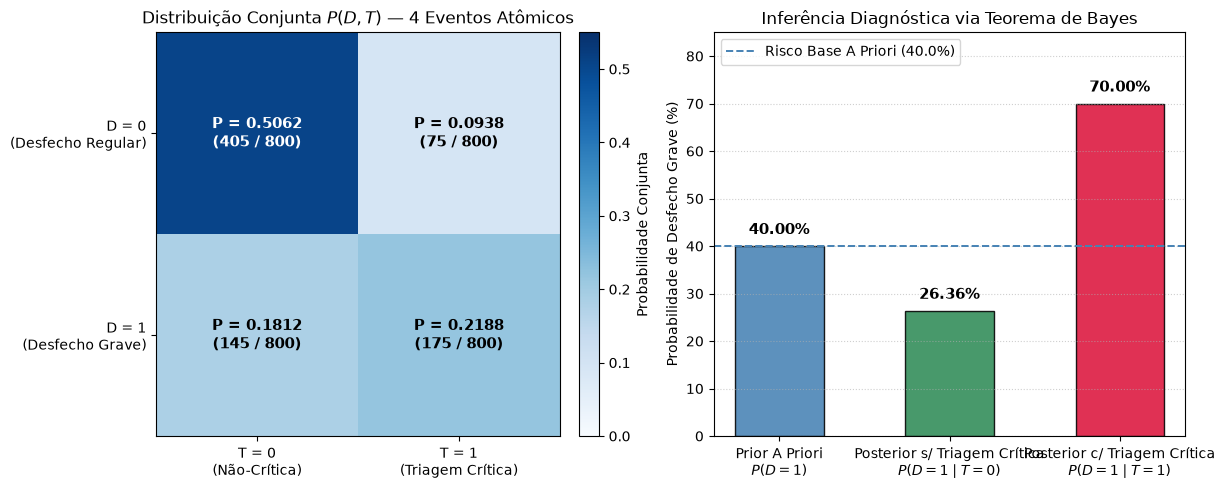

In [6]:
# ==============================================================================
# CÉLULA 6: Visualização Gráfica — Distribuição Conjunta P(D, T) e Atualização Bayesiana
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))

# Subplot 1: Heatmap da Distribuição Conjunta P(D, T)
im = axes[0].imshow(tabela_conjunta, cmap="Blues", vmin=0.0, vmax=0.55)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["T = 0\n(Não-Crítica)", "T = 1\n(Triagem Crítica)"])
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["D = 0\n(Desfecho Regular)", "D = 1\n(Desfecho Grave)"])
axes[0].set_title("Distribuição Conjunta $P(D, T)$ — 4 Eventos Atômicos")

for d in [0, 1]:
    for t in [0, 1]:
        val = tabela_conjunta[d, t]
        cnt = int(round(val * N))
        cor_txt = "white" if val > 0.35 else "black"
        axes[0].text(t, d, f"P = {val:.4f}\n({cnt} / {N})", ha="center", va="center", color=cor_txt, fontsize=11, fontweight="bold")

fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="Probabilidade Conjunta")

# Subplot 2: Atualização Bayesiana (Prior vs. Posteriores Diagnósticas)
categorias = [
    "Prior A Priori\n$P(D=1)$",
    "Posterior s/ Triagem Crítica\n$P(D=1 \\mid T=0)$",
    "Posterior c/ Triagem Crítica\n$P(D=1 \\mid T=1)$",
]
valores_pct = [100 * p_d1, 100 * p_d1_dado_t0_bayes, 100 * p_d1_dado_t1_bayes]
cores = ["steelblue", "seagreen", "crimson"]

barras = axes[1].bar(categorias, valores_pct, color=cores, width=0.52, edgecolor="black", alpha=0.88)
axes[1].axhline(100 * p_d1, color="steelblue", linestyle="--", linewidth=1.4, label=f"Risco Base A Priori ({100*p_d1:.1f}%)")
axes[1].set_ylim(0, 85)
axes[1].set_ylabel("Probabilidade de Desfecho Grave (%)")
axes[1].set_title("Inferência Diagnóstica via Teorema de Bayes")
axes[1].grid(axis="y", linestyle=":", alpha=0.6)
axes[1].legend(loc="upper left")

for barra, v in zip(barras, valores_pct):
    axes[1].text(barra.get_x() + barra.get_width() / 2, v + 1.8, f"{v:.2f}%", ha="center", va="bottom", fontsize=10.5, fontweight="bold")

plt.tight_layout()
plt.savefig("fig_etapa3_probabilidades_bayes.png", dpi=300)
plt.show()

## Discussão Teórica (Seção 6.4) — Por que a Lógica de Primeira Ordem (LPO) Não Expressa *"70% de Chance"*?

Na Lógica Proposicional e na Lógica de Primeira Ordem (LPO), as sentenças possuem semântica estritamente **ontológica e bivalente** ($\text{Verdadeiro}$ ou $\text{Falso}$ em cada modelo possível). Se tentarmos formalizar a regra médica do nosso domínio como uma implicação universal:
$$\forall x \; \text{TriagemCritica}(x) \Rightarrow \text{DesfechoGrave}(x)$$
essa sentença é **refutada (Falsa)** pela existência dos $75$ pacientes da base SIH/SUS que ingressaram com `TriagemCritica` ($T=1$), mas tiveram evolução regular ($D=0$). Conforme sistematizado por Russell & Norvig (Capítulo 12 — *Quantifying Uncertainty*), a incapacidade da LPO de operar em domínios reais decorre de três fatores fundamentais:

1. **Preguiça (*Laziness*):** É computacional e cognitivamente inviável enumerar na antecedente da regra lógica a lista completa e sem exceções de todas as qualificações clínicas necessárias para garantir um desfecho com $100\%$ de certeza;
2. **Ignorância Teórica (*Theoretical Ignorance*):** A ciência médica não possui um modelo determinístico completo da fisiopatologia humana capaz de prever sem erro a resposta imunológica e hemodinâmica de cada indivíduo;
3. **Ignorância Prática (*Practical Ignorance*):** Mesmo que todas as leis fisiológicas fossem conhecidas, no momento da admissão hospitalar não dispomos do resultado de todos os exames laboratoriais, genéticos e microbiológicos daquele paciente específico.

A **Teoria da Probabilidade** resolve esse impasse ao substituir o compromisso ontológico binário por **graus de crença (*degrees of belief*)** contínuos em $[0, 1]$ resumindo a incerteza residual sobre os fatores não observados: em vez de uma regra lógica quebradiça, o Teorema de Bayes fornece a probabilidade condicional exata **$P(D=1 \mid T=1) = 0{,}7000$ ($70{,}0\%$ de chance)**, permitindo tomada de decisão racional sob incerteza.